# **Шешім ағашының регрессоры** — баға, ұпай, температура сияқты үздіксіз сандық мәндерді болжауға арналған модель. Ол ағаш тәрізді құрылымды пайдаланады.

Модель кіріс белгілерінен алынған қарапайым шарттар бойынша деректерді шағын топтарға бөледі. Осылайша болжам қатесін азайтуға тырысады. Әрбір тармақтың соңында **жапырақ түйіні** орналасады. Модельдің болжамы — әдетте осы жапыраққа түскен мәндердің орташа шамасы.

**Мысалы**, үй бағасын болжау кезінде мына белгілер қолданылуы мүмкін:

- үйдің ауданы;
- орналасқан жері;
- үйдің жасы.

Ағаш үйлерді алдымен орналасқан жері, одан кейін ауданы, соңында жасы бойынша бөлуі мүмкін. Енді осы модельді бағдарламалық түрде жүзеге асырайық.

## 1-қадам: Қажетті кітапханаларды импорттау

Келесі кітапханаларды қолданамыз:

- [**NumPy**](https://www.geeksforgeeks.org/numpy/python-numpy/) — сандық есептеулер жүргізу және массивтермен жұмыс істеу үшін;
- [**Matplotlib**](https://www.geeksforgeeks.org/python/python-introduction-matplotlib/) — графиктер құру және нәтижелерді визуализациялау үшін;
- [**scikit-learn**](https://www.geeksforgeeks.org/machine-learning/learning-model-building-scikit-learn-python-machine-learning-library/) модульдері — модель құру, деректерді оқыту және тест жиындарына бөлу, шешім ағашын көрсету және модельдің сапасын бағалау үшін.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

## 2-қадам: Жасанды деректер жиынтығын құру

Бұл қадамда `NumPy` кітапханасының көмегімен жасанды деректер жиынтығын құрамыз.

- `X` — 0 мен 5 аралығынан кездейсоқ алынған және өсу ретімен сұрыпталған кіріс мәндері;
- `y` — `X` мәндеріне тәуелді, кездейсоқ шу қосылған синус функциясы;
- нүктелік график (`scatter plot`) кіріс белгілері өзгерген кезде мақсатты `y` мәндерінің қалай өзгеретінін көрсетеді.

Қарапайым тілмен айтқанда, `X` — модельге берілетін дерек, ал `y` — модель болжауы керек нәтиже. Кездейсоқ шу нақты өмірдегі деректердің мінсіз болмайтынын көрсету үшін қосылады.

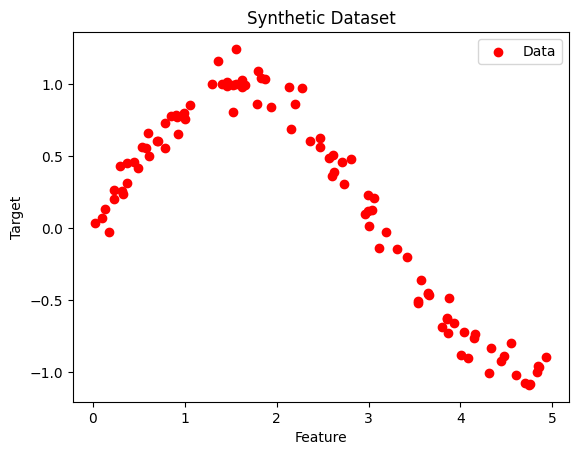

In [2]:
np.random.seed(42)
X = np.sort(5 * np.random.rand(100, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.1, X.shape[0])

plt.scatter(X, y, color='red', label='Data')
plt.title("Synthetic Dataset")
plt.xlabel("Feature")
plt.ylabel("Target")
plt.legend()
plt.show()

## 3-қадам: Деректер жиынтығын бөлу

`train_test_split` функциясының көмегімен деректерді екі бөлікке бөлеміз:

- **70% — оқыту деректері:** модель осы деректер арқылы үйренеді;
- **30% — тестілеу деректері:** оқытылған модельдің жаңа деректердегі жұмыс сапасын тексеру үшін қолданылады.

`random_state=42` параметрі деректердің әр іске қосылған сайын бірдей бөлінуін қамтамасыз етеді. Бұл тәжірибенің нәтижесін қайтадан алуға және салыстыруға мүмкіндік береді.

Нәтижесінде төрт жиын пайда болады:

- `X_train` — оқытуға арналған кіріс деректері;
- `X_test` — тестілеуге арналған кіріс деректері;
- `y_train` — оқыту деректерінің дұрыс жауаптары;
- `y_test` — тест деректерінің дұрыс жауаптары.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

## 4-қадам: Шешім ағашының регрессорын құру

Бұл қадамда `scikit-learn` кітапханасындағы `DecisionTreeRegressor` класын пайдаланып, регрессиялық шешім ағашының моделін құрамыз.

Сонымен қатар `max_depth=4` параметрін орнатамыз. Бұл параметр ағаштың максималды тереңдігін, яғни түбірден төмен қарай ең көбі қанша деңгей құра алатынын шектейді.

Қарапайым тілмен айтқанда:

- `max_depth` кішкентай болса, ағаш қарапайым болады, бірақ деректердегі кейбір заңдылықтарды байқамауы мүмкін;
- `max_depth` өте үлкен болса, ағаш күрделеніп, оқыту деректерін жаттап алуы мүмкін;
- `max_depth=4` — ағаштың тереңдігін төрт деңгеймен шектейді.

> Ескерту: `max_depth=4` деген ағашта төрт тармақ болады деген сөз емес. Бұл — ағаштың ең ұзын жолының тереңдігі төрт деңгейден аспайды деген мағына.

## 5-қадам: Шешім ағашының регрессиялық моделін оқыту

Модельді `X_train` және `y_train` деректерімен `.fit()` әдісі арқылы оқытамыз. Осылайша модель кіріс белгілері мен мақсатты мән арасындағы байланысты үйренеді.

In [5]:
regressor = DecisionTreeRegressor(random_state=42)
regressor.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

6-қадам: Жаңа мәнді болжау
Енді оқытылған модельдің predict() функциясын қолданып, жаңа мәнді болжаймыз.

Содан кейін модельдің бұрын көрмеген тест деректеріндегі дәлдігін тексеру үшін орташа квадраттық қатені (MSE) есептейміз. MSE мәні неғұрлым төмен болса, модельдің болжамы соғұрлым жақсы болады.

In [6]:
y_pred = regressor.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse:.4f}")

Mean Squared Error: 0.0132


## 7-қадам: Нәтижені визуализациялау

Шешім ағашының деректерге қаншалықты жақсы сәйкес келетінін және негізгі заңдылықты қалай анықтайтынын көру үшін модель болжамдарын графикте көрсетеміз.

Графикте шешім ағашының болжамдары деректердің бөлінуіне байланысты сатылы бөліктер түрінде өзгеретіні көрінеді.

/tmp/ipykernel_2012/3277648091.py:1: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(X), max(X), 0.01)[:, np.newaxis]


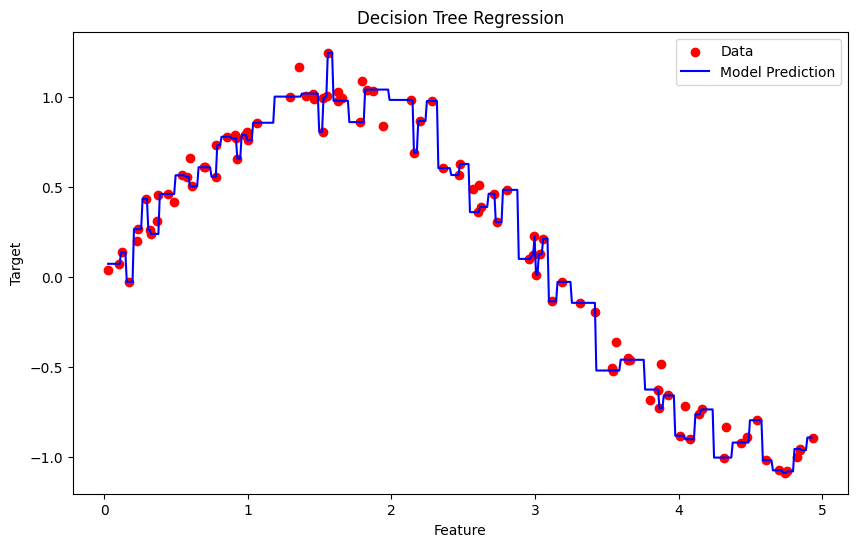

In [7]:
X_grid = np.arange(min(X), max(X), 0.01)[:, np.newaxis]
y_grid_pred = regressor.predict(X_grid)

plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='red', label='Data')
plt.plot(X_grid, y_grid_pred, color='blue', label='Model Prediction')
plt.title("Decision Tree Regression")
plt.xlabel("Feature")
plt.ylabel("Target")
plt.legend()
plt.show()

## 8-қадам: Шешім ағашының құрылымын көрсету

Модельдің құрылымын жақсырақ түсіну үшін `plot_tree()` функциясын қолданып, шешім ағашын визуализациялаймыз.

Бұл сызбада:

- әр түйіндегі бөлу шарты;
- деректердің қандай ереже бойынша бөлінетіні;
- әр түйіндегі үлгілер саны;
- жапырақ түйіндеріндегі болжам мәндері көрсетіледі.

Осылайша модельдің деректерді қалай бөліп, болжамды қалай жасайтынын көруге болады.

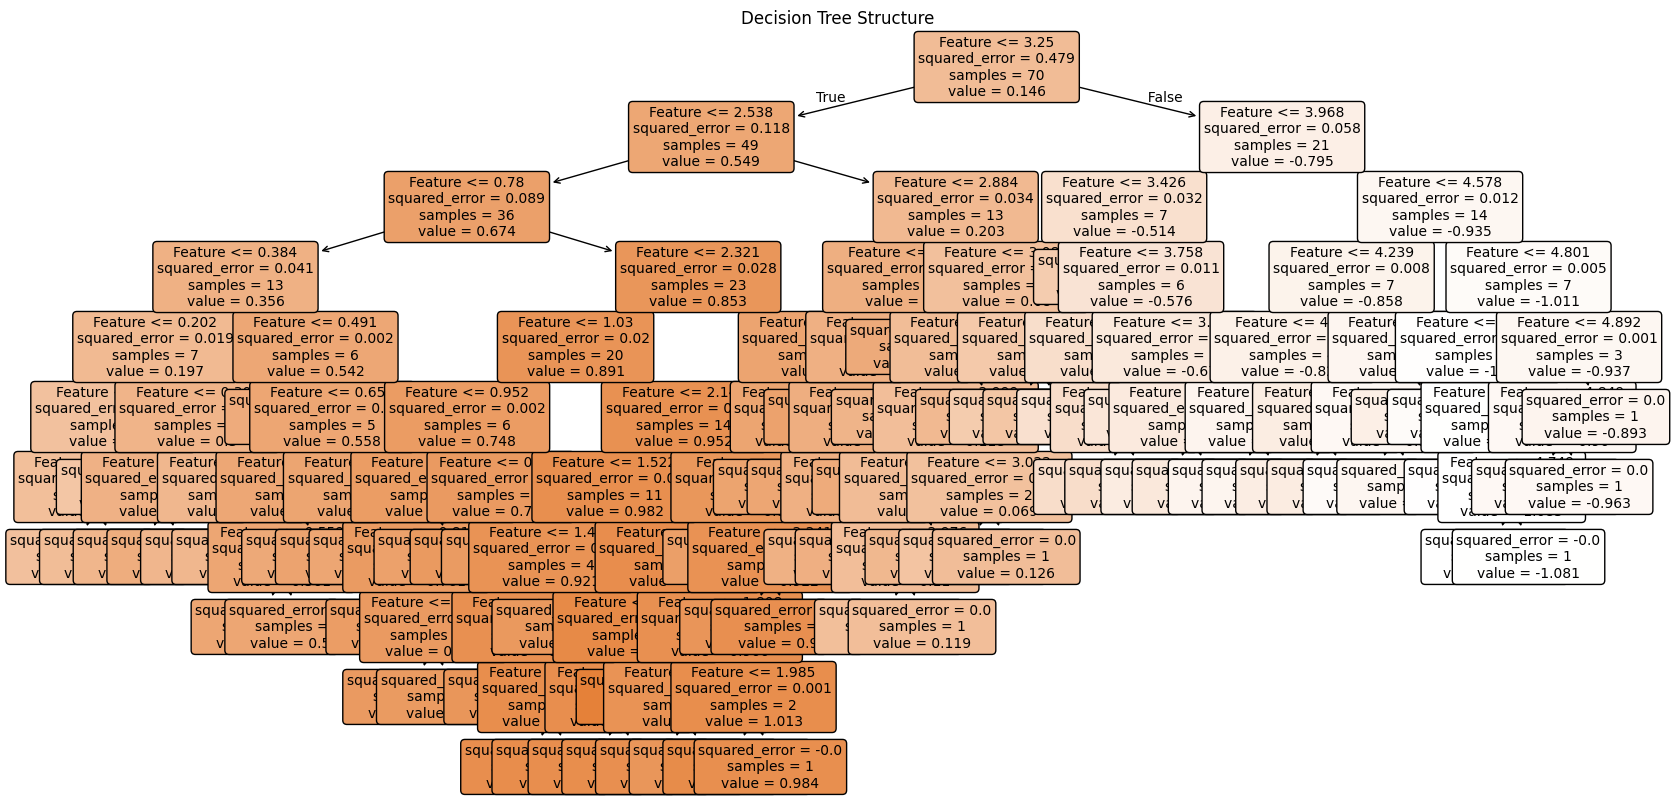

In [8]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    regressor,
    feature_names=["Feature"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure")
plt.show()

**Шешім ағашының регрессиясы** үздіксіз сандық мәндерді болжау үшін қолданылады және деректердегі сызықтық емес заңдылықтарды тиімді анықтай алады.

Ағаш тәрізді құрылымының арқасында модельдің жұмысын түсіндіру оңай. Біз белгілі бір шешімнің не себепті қабылданғанын және нақты болжамның қалай алынғанын көре аламыз.

Бұл ақпаратты модельдің жұмысын талдау, параметрлерін реттеу және нәтижесін жақсарту үшін пайдалануға болады.